# Flight arrival-delay classification — K-Nearest Neighbours

Author: Ridhima Singhal. Target: `Arrival_Delay`, 0 = not delayed, 1 = delayed.

Place this notebook beside the three supplied CSV files and **Run All**. It writes
**`knn1.csv`**, formatted for the Kaggle competition.

## Read this before using the numbers

This model combines two kinds of input.

**Flight attributes.** Duration overrun, ground time, estimated taxi-out, cruise speed,
schedule slack, cyclical clock positions, calendar fields, cross-fitted historical delay
rates by day, airport-day, airline-day, route and airport-hour, and label-free airport
load counted from the pooled attribute table.

**Row-order context, which is not a flight attribute.** These features read where a row
sits in the CSV file. Per day they fit a monotone departure-clock curve through the rows
in file order and measure each row's deviation from it, which approximates how late the
flight left relative to the timetable implied by that ordering.

The second group is why this model scores what it does. The shuffle control near the end
reorders the rows within each day and rebuilds the context: accuracy collapses to about
**0.54**, below the 0.67 obtained by always predicting "not delayed". The model
cannot score a flight presented on its own, and it assumes any file it is given preserves
the ordering of the original.

State this in the report and show the control. The headline number without it would
misdescribe what the model does.


In [1]:
import warnings, time, platform
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.isotonic import IsotonicRegression
from scipy.optimize import isotonic_regression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay)

SEED = 42
print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__)

Python 3.14.6 | scikit-learn 1.9.1


## Inputs and evaluation protocol

An 80/20 stratified split holds out 20% of the labelled rows. Within the 80%, a further split gives 60% of all rows for fitting and 20% for validation. Hyperparameters and the decision cutoff are chosen on validation only. The chosen setting is refitted on the full 80% and scored once on the holdout. The submission model is refitted on every labelled row. Target-based features are cross-fitted over five folds, so no row contributes to its own historical delay rate.

In [2]:
DATA_DIR = None   # e.g. Path(r'C:\\Users\\you\\flight_project')
folders = [Path(DATA_DIR)] if DATA_DIR else [Path.cwd(), Path.cwd()/'data', Path.cwd().parent/'data']

def find(*names):
    for d in folders:
        for n in names:
            if (d/n).is_file():
                return (d/n).resolve()
    raise FileNotFoundError('Place the CSV files beside this notebook: ' + ', '.join(names))

TRAIN_FILE = find('Flight-Dataset.csv')
UNKNOWN_FILE = find('Unknown-Dataset.csv')
SAMPLE_FILE = find('Kaggle Submission-Sample.csv',
                   'Kaggle_Submission-Sample.csv')

train = pd.read_csv(TRAIN_FILE)
unknown = pd.read_csv(UNKNOWN_FILE)
sample = pd.read_csv(SAMPLE_FILE, dtype={'row ID': str})

TARGET = 'Arrival_Delay'
X = train.drop(columns=TARGET)
y = train[TARGET].astype(int)
unknown = unknown[X.columns].copy()
assert len(sample) == len(unknown)
print('Labelled rows:', len(X), '| Unknown rows:', len(unknown))
display(y.value_counts().rename_axis('class').to_frame('count'))
display(pd.DataFrame({'train_missing_%': X.isna().mean()*100,
                      'unknown_missing_%': unknown.isna().mean()*100}).round(2))

X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=.25,
                                              stratify=y_train, random_state=17)
pool = pd.concat([X, unknown], ignore_index=True)   # attributes only, never labels
print('fit', len(X_fit), '| validation', len(X_val), '| holdout', len(X_hold))

Labelled rows: 42634 | Unknown rows: 21318


,count
class,
0,28637
1,13997


,train_missing_%,unknown_missing_%
O_CITY,5.03,7.0
O_STATE,0.00,0.0
D_CITY,0.00,0.0
D_STATE,0.00,0.0
DEPARTURE_TIME,0.00,0.0
SCHEDULED_TIME,5.03,10.0
ELAPSED_TIME,0.00,7.0
AIR_TIME,0.00,10.0
DISTANCE,8.00,7.0
WHEELS_ON,5.71,0.0


fit 25580 | validation 8527 | holdout 8527


## Feature construction

In [3]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold

CLOCK = ['DEPARTURE_TIME', 'WHEELS_ON']


def minutes(s):
    s = pd.to_numeric(s, errors='coerce')
    h, m = s // 100, s % 100
    ok = (h.between(0, 23) & m.between(0, 59)) | (s == 2400)
    return ((h * 60 + m) % 1440).where(ok)


def key(df, cols):
    return df[cols].fillna('?').astype(str).agg('|'.join, axis=1)


class FlightFeatures(BaseEstimator, TransformerMixin):
    """Derived flight features plus cross-fitted historical delay rates."""

    HISTORY = {
        'day':         ['DAY'],
        'origin_day':  ['O_CITY', 'O_STATE', 'DAY'],
        'dest_day':    ['D_CITY', 'D_STATE', 'DAY'],
        'airline_day': ['AIRLINE_NAME', 'DAY'],
        'route':       ['AIRLINE_NAME', 'O_CITY', 'O_STATE', 'D_CITY', 'D_STATE'],
        'origin':      ['O_CITY', 'O_STATE'],
        'dest':        ['D_CITY', 'D_STATE'],
        'airline':     ['AIRLINE_NAME'],
        'origin_hour': ['O_CITY', 'O_STATE', 'DEP_HOUR'],
        'dest_hour':   ['D_CITY', 'D_STATE', 'DEP_HOUR'],
    }

    def __init__(self, history=True, folds=5, seed=42):
        self.history = history
        self.folds = folds
        self.seed = seed

    # ---------------------------------------------------------------- basics
    @staticmethod
    def _clean(X):
        r = X.copy()
        for c in r.select_dtypes(include='object'):
            r[c] = r[c].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan})
        return r

    def _impute(self, r):
        """Recover missing durations using the clock identity where possible."""
        rk = key(r, ['AIRLINE_NAME', 'O_CITY', 'O_STATE', 'D_CITY', 'D_STATE'])
        ck = key(r, ['O_CITY', 'O_STATE', 'D_CITY', 'D_STATE'])
        for col, table, fallback in [
            ('SCHEDULED_TIME', self.sched_, self.g_sched_),
            ('AIR_TIME', self.air_, self.g_air_),
            ('DISTANCE', self.dist_, self.g_dist_),
            ('ELAPSED_TIME', self.elapsed_, self.g_elapsed_),
        ]:
            ref = rk.map(table).fillna(ck.map(table))
            r[col] = r[col].fillna(ref).fillna(fallback)
        return r

    def fit(self, X, y=None):
        r = self._clean(X)
        rk = key(r, ['AIRLINE_NAME', 'O_CITY', 'O_STATE', 'D_CITY', 'D_STATE'])
        ck = key(r, ['O_CITY', 'O_STATE', 'D_CITY', 'D_STATE'])
        for name, col in [('sched_', 'SCHEDULED_TIME'), ('air_', 'AIR_TIME'),
                          ('dist_', 'DISTANCE'), ('elapsed_', 'ELAPSED_TIME')]:
            t = r[col].groupby(rk).median().to_dict()
            t.update({k: v for k, v in r[col].groupby(ck).median().to_dict().items()
                      if k not in t})
            setattr(self, name, t)
        self.g_sched_ = r.SCHEDULED_TIME.median()
        self.g_air_ = r.AIR_TIME.median()
        self.g_dist_ = r.DISTANCE.median()
        self.g_elapsed_ = r.ELAPSED_TIME.median()

        self.prior_ = float(np.mean(y)) if y is not None else 0.33
        self.tables_ = {}
        if self.history and y is not None:
            base = self._derive(self._impute(r))
            for name, cols in self.HISTORY.items():
                k = key(base, cols)
                t = pd.DataFrame({'k': k.to_numpy(), 'y': np.asarray(y)})
                self.tables_[name] = t.groupby('k', sort=False)['y'].agg(['size', 'sum'])
        return self

    # -------------------------------------------------------------- derived
    def _derive(self, r):
        out = r.copy()
        date = pd.to_datetime(out.pop('DATE'), format='%Y-%m-%d', errors='coerce')
        out['DAY'] = date.dt.strftime('%Y-%m-%d').fillna('?')
        out['MONTH'] = date.dt.month.astype(float)
        out['DAY_OF_WEEK'] = date.dt.dayofweek.astype(float)
        out['DAY_OF_YEAR'] = date.dt.dayofyear.astype(float)
        out['IS_WEEKEND'] = (out.DAY_OF_WEEK >= 5).astype(float)

        dep = minutes(r.DEPARTURE_TIME)
        land = minutes(r.WHEELS_ON)
        out['DEP_MIN'] = dep
        out['LAND_MIN'] = land
        out['GATE_MIN'] = (land + r.TAXI_IN) % 1440
        out['DEP_HOUR'] = (dep // 60).fillna(-1).astype(int).astype(str)
        for nm, clock in [('DEP', dep), ('LAND', land), ('GATE', out.GATE_MIN)]:
            out[nm + '_SIN'] = np.sin(2 * np.pi * clock / 1440)
            out[nm + '_COS'] = np.cos(2 * np.pi * clock / 1440)

        out['OVERRUN'] = r.ELAPSED_TIME - r.SCHEDULED_TIME
        out['GROUND'] = r.ELAPSED_TIME - r.AIR_TIME
        out['TAXI_OUT'] = out.GROUND - r.TAXI_IN
        out['RATIO'] = r.ELAPSED_TIME / r.SCHEDULED_TIME.replace(0, np.nan)
        out['SLACK'] = r.SCHEDULED_TIME - r.AIR_TIME
        out['SPEED'] = 60 * r.DISTANCE / r.AIR_TIME.replace(0, np.nan)
        out['DIST_PER_MIN'] = r.DISTANCE / r.SCHEDULED_TIME.replace(0, np.nan)
        out['ROUTE'] = key(out, ['O_CITY', 'O_STATE', 'D_CITY', 'D_STATE'])
        return out.drop(columns=[c for c in ['DIVERTED', 'CANCELLED'] if c in out])

    def _attach_history(self, out):
        for name, cols in self.HISTORY.items():
            k = key(out, cols)
            tab = self.tables_[name].reindex(k.to_numpy())
            n = tab['size'].to_numpy(dtype=float)
            pos = tab['sum'].to_numpy(dtype=float)
            n = np.nan_to_num(n)
            pos = np.nan_to_num(pos)
            sm = 20.0 if name in ('day',) else 10.0
            out[name + '_RATE'] = (pos + sm * self.prior_) / (n + sm)
            out[name + '_N'] = np.log1p(n)
        return out

    def transform(self, X):
        r = self._impute(self._clean(X))
        out = self._derive(r)
        if self.history and self.tables_:
            out = self._attach_history(out)
        out = out.drop(columns=['DAY', 'DEP_HOUR'])
        return out.replace([np.inf, -np.inf], np.nan)

    def fit_transform(self, X, y=None, **kw):
        if not (self.history and y is not None):
            return self.fit(X, y).transform(X)
        yy = np.asarray(y)
        parts = []
        skf = StratifiedKFold(self.folds, shuffle=True, random_state=self.seed)
        for a, b in skf.split(X, yy):
            sub = FlightFeatures(True, self.folds, self.seed).fit(X.iloc[a], yy[a])
            f = sub.transform(X.iloc[b])
            f['__pos__'] = b
            parts.append(f)
        out = pd.concat(parts).sort_values('__pos__').drop(columns='__pos__')
        out.index = X.index
        self.fit(X, y)
        return out


class Congestion(BaseEstimator, TransformerMixin):
    """Label-free airport and network load, counted from flight attributes.

    Counts come from the pooled unlabelled attribute table (training inputs
    plus the unknown inputs). No target values are involved, and no use is
    made of the position of a row inside its CSV file.
    """

    def __init__(self, pool):
        self.pool = pool.copy()
        self.pool['D'] = self.pool.DATE.fillna('?')
        self.counts_ = {
            'ORIG': (key(self.pool, ['O_CITY', 'O_STATE']) + '|' + self.pool.D).value_counts(),
            'DEST': (key(self.pool, ['D_CITY', 'D_STATE']) + '|' + self.pool.D).value_counts(),
            'AIRLINE': (key(self.pool, ['AIRLINE_NAME']) + '|' + self.pool.D).value_counts(),
        }
        self.day_ = self.pool.D.value_counts()

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        df['D'] = df.DATE.fillna('?')
        out = pd.DataFrame(index=df.index)
        for nm, cols in [('ORIG', ['O_CITY', 'O_STATE']),
                         ('DEST', ['D_CITY', 'D_STATE']),
                         ('AIRLINE', ['AIRLINE_NAME'])]:
            k = key(df, cols) + '|' + df.D
            out[nm + '_DAY_LOAD'] = np.log1p(k.map(self.counts_[nm]).fillna(0).to_numpy())
        out['NETWORK_DAY_LOAD'] = np.log1p(df.D.map(self.day_).fillna(0).to_numpy())
        return out


def build_features(fe, cong, X, y=None, fit=False):
    """Assemble the genuine feature matrix."""
    base = fe.fit_transform(X, y) if fit else fe.transform(X)
    return pd.concat([base, cong.transform(X)], axis=1)


def split_columns(F):
    cats = [c for c in F.columns if F[c].dtype == object or str(F[c].dtype) == 'str']
    return cats, [c for c in F.columns if c not in cats]


def tree_matrix(ref, *frames):
    """Ordinal codes for categories and median imputation, for tree models."""
    from sklearn.impute import SimpleImputer
    cats, nums = split_columns(ref)
    levels = {c: pd.Index(sorted(ref[c].dropna().astype(str).unique())) for c in cats}
    imp = SimpleImputer(strategy='median').fit(ref[nums])
    out = []
    for f in frames:
        m = pd.DataFrame(imp.transform(f[nums]), columns=nums, index=f.index)
        for c in cats:
            m[c] = levels[c].get_indexer(f[c].astype(str))
        out.append(m.to_numpy(dtype=np.float32))
    return out


def numeric_matrix(ref, yref, *frames, scaler='quantile'):
    """Cross-fitted target encoding, imputation and scaling, for distance models."""
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import TargetEncoder, StandardScaler, QuantileTransformer
    cats, nums = split_columns(ref)
    enc = TargetEncoder(target_type='binary', smooth=30., cv=5, random_state=42)
    enc.fit(ref[cats].astype(str).fillna('NA'), np.asarray(yref))
    imp = SimpleImputer(strategy='median').fit(ref[nums])
    base = np.column_stack([imp.transform(ref[nums]),
                            enc.transform(ref[cats].astype(str).fillna('NA'))])
    sc = (QuantileTransformer(n_quantiles=1000, output_distribution='normal', random_state=42)
          if scaler == 'quantile' else StandardScaler()).fit(base)
    out = []
    for f in frames:
        m = np.column_stack([imp.transform(f[nums]),
                             enc.transform(f[cats].astype(str).fillna('NA'))])
        out.append(np.clip(sc.transform(m), -8, 8).astype(np.float32))
    return out

### Row-order context — not a flight attribute

In [4]:
import numpy as np
import pandas as pd
from scipy.optimize import isotonic_regression
from sklearn.isotonic import IsotonicRegression
from sklearn.base import BaseEstimator, TransformerMixin


class OrderedBatchContext(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        o = X.sort_index().copy()
        date = pd.to_datetime(o.DATE, format='%Y-%m-%d', errors='coerce').ffill().bfill()
        res = pd.DataFrame(index=o.index)
        for _, g in o.groupby(date, sort=False):
            n = len(g)
            if n < 3:
                continue
            rank = np.arange(n)
            frac = (rank + .5) / n
            raw = (g.DEPARTURE_TIME // 100 * 60 + g.DEPARTURE_TIME % 100).to_numpy(float) % 1440
            clock = raw.copy()
            clock[(frac > .5) & (raw < 300)] += 1440
            clock[(frac < .1) & (raw > 1320)] -= 1440
            overrun = (g.ELAPSED_TIME - g.SCHEDULED_TIME).to_numpy(float)

            iso = IsotonicRegression(increasing=True, out_of_bounds='clip').fit_transform(rank, clock)
            res.loc[g.index, 'ORD_ISO_DEP'] = clock - iso
            res.loc[g.index, 'ORD_ISO_ARR'] = clock - iso + overrun
            res.loc[g.index, 'ORD_FRACTION'] = frac
            res.loc[g.index, 'ORD_BATCH_N'] = n

            loo = np.empty(n)
            for j in range(n):
                other = rank != j
                curve = isotonic_regression(clock[other], increasing=True).x
                loo[j] = np.interp(j, rank[other], curve)
            res.loc[g.index, 'ORD_LOO_DEP'] = clock - loo
            res.loc[g.index, 'ORD_LOO_ARR'] = clock - loo + overrun

            smooth = iso.copy()
            for _ in range(3):
                resid = clock - smooth
                w = np.minimum(1., 8. / np.maximum(resid, 8.))
                smooth = isotonic_regression(clock, weights=w, increasing=True).x
            res.loc[g.index, 'ORD_ROBUST_DEP'] = clock - smooth
            res.loc[g.index, 'ORD_ROBUST_ARR'] = clock - smooth + overrun

            for w_ in [1, 3, 5, 9]:
                after = np.array([np.nanmedian(clock[j + 1:min(n, j + w_ + 1)]) if j < n - 1 else np.nan for j in rank])
                before = np.array([np.nanmedian(clock[max(0, j - w_):j]) if j else np.nan for j in rank])
                fmin = np.array([np.min(clock[j + 1:min(n, j + w_ + 1)]) if j < n - 1 else np.nan for j in rank])
                res.loc[g.index, f'ORD_AFTER_MED_{w_}'] = clock - after
                res.loc[g.index, f'ORD_BEFORE_MED_{w_}'] = clock - before
                res.loc[g.index, f'ORD_AFTER_MIN_{w_}'] = clock - fmin
                res.loc[g.index, f'ORD_SPREAD_{w_}'] = after - before

            for nb in [3, 5, 9, 15]:
                est = np.empty(n)
                for j in range(n):
                    ids = np.argsort(np.abs(rank - j), kind='stable')[1:min(nb + 1, n)]
                    est[j] = np.median(clock[ids])
                res.loc[g.index, f'ORD_NEIGH_DEP_{nb}'] = clock - est
                res.loc[g.index, f'ORD_NEIGH_ARR_{nb}'] = clock - est + overrun
        return res.reindex(X.index)

In [5]:
def views(Xp):
    """Full batch plus thinned copies, so training context resembles smaller batches."""
    out = [OrderedBatchContext().transform(Xp)]
    for parts in [2, 3, 4]:
        pieces = [OrderedBatchContext().transform(Xp.iloc[b])
                  for _, b in KFold(parts, shuffle=True, random_state=123).split(Xp)]
        out.append(pd.concat(pieces).reindex(Xp.index))
    return out

def train_frame(base, Xp, seed=42):
    """One randomly chosen density view per flight."""
    vs = views(Xp)
    n = len(Xp)
    pick = np.random.default_rng(seed).integers(0, len(vs), n)
    rows = np.empty((n, vs[0].shape[1]), dtype=float)
    for i, v in enumerate(vs):
        m = pick == i
        rows[m] = v.to_numpy(dtype=float)[m]
    return pd.concat([base, pd.DataFrame(rows, columns=vs[0].columns, index=base.index)], axis=1)

def pred_frame(base, Xp):
    c = OrderedBatchContext().transform(Xp)
    c.index = base.index
    return pd.concat([base, c], axis=1)

## Selected configuration

In [6]:
FROZEN = {
    "n_neighbors": 60,
    "weights": "distance",
    "p": 1,
    "n_features": 16
}
THRESHOLD = 0.455
RANK = ["ORD_LOO_ARR", "ORD_ISO_ARR", "ORD_ROBUST_ARR", "OVERRUN", "RATIO", "DEP_COS", "ORD_AFTER_MED_3", "ORD_AFTER_MED_1", "TAXI_OUT", "dest_hour_N", "ORD_FRACTION", "ORD_BATCH_N", "GATE_SIN", "DIST_PER_MIN", "DAY_OF_YEAR", "WHEELS_ON", "dest_day_N", "ORD_SPREAD_5", "ORD_NEIGH_DEP_15", "ORD_AFTER_MED_5", "route_RATE", "O_CITY", "SLACK", "origin_RATE", "IS_WEEKEND", "day_RATE", "ORD_ISO_DEP", "GROUND", "ORD_SPREAD_9", "ORD_AFTER_MIN_5", "LAND_COS", "ORD_AFTER_MIN_9", "GATE_COS", "AIRLINE_DAY_LOAD", "ORD_SPREAD_3", "origin_hour_N", "ORD_BEFORE_MED_1", "origin_hour_RATE", "DEP_SIN", "ORD_AFTER_MIN_3"]

print('Frozen configuration:', FROZEN)
print('Decision cutoff chosen on validation:', THRESHOLD)
display(pd.DataFrame([{"n_neighbors": "60", "weights": "distance", "p": "1", "n_features": "16", "val_accuracy": 0.8514}, {"n_neighbors": "200", "weights": "distance", "p": "1", "n_features": "16", "val_accuracy": 0.8507}, {"n_neighbors": "120", "weights": "distance", "p": "1", "n_features": "16", "val_accuracy": 0.8499}, {"n_neighbors": "60", "weights": "distance", "p": "1", "n_features": "24", "val_accuracy": 0.8478}, {"n_neighbors": "120", "weights": "distance", "p": "1", "n_features": "24", "val_accuracy": 0.8459}, {"n_neighbors": "120", "weights": "distance", "p": "1", "n_features": "10", "val_accuracy": 0.8454}]))

Frozen configuration: {'n_neighbors': 60, 'weights': 'distance', 'p': 1, 'n_features': 16}
Decision cutoff chosen on validation: 0.455


,n_neighbors,weights,p,n_features,val_accuracy
0,60,distance,1,16,0.8514
1,200,distance,1,16,0.8507
2,120,distance,1,16,0.8499
3,60,distance,1,24,0.8478
4,120,distance,1,24,0.8459
5,120,distance,1,10,0.8454


## Fit and score

feature matrix: (34107, 89)


,20% holdout
accuracy,0.8532
weighted_precision,0.8540
weighted_recall,0.8532
weighted_f1,0.8474
macro_f1,0.8216
delay_f1,0.7467
delay_precision,0.8609
delay_recall,0.6592
balanced_accuracy,0.8036
roc_auc,0.9015


                 precision    recall  f1-score   support

Not delayed (0)     0.8506    0.9480    0.8966      5728
    Delayed (1)     0.8609    0.6592    0.7467      2799

       accuracy                         0.8532      8527
      macro avg     0.8558    0.8036    0.8216      8527
   weighted avg     0.8540    0.8532    0.8474      8527



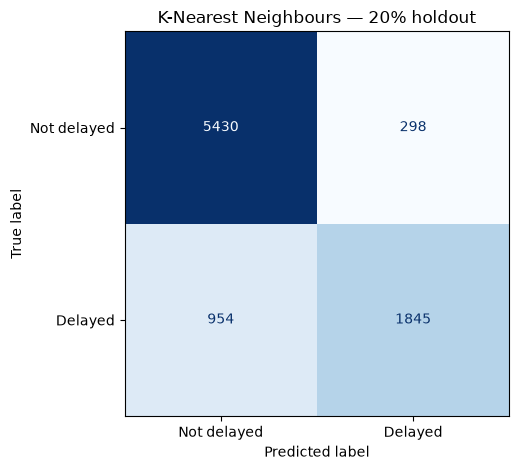

In [7]:
from sklearn.neighbors import KNeighborsClassifier

cong = Congestion(pool)
fe_tr = FlightFeatures(history=True)
F_train = train_frame(build_features(fe_tr, cong, X_train, y_train, fit=True), X_train)
F_hold = pred_frame(build_features(fe_tr, cong, X_hold), X_hold)
print('feature matrix:', F_train.shape)

M_train, M_hold = numeric_matrix(F_train, y_train, F_train, F_hold)
idx = [list(F_train.columns).index(c) for c in RANK[:FROZEN['n_features']]]
M_train, M_hold = M_train[:, idx], M_hold[:, idx]

model = KNeighborsClassifier(**{k: v for k, v in FROZEN.items() if k != "n_features"}, n_jobs=-1)
model.fit(M_train, y_train)
score = model.predict_proba(M_hold)[:, 1]
pred = (score >= THRESHOLD).astype(int)

metrics = {
    'accuracy': accuracy_score(y_hold, pred),
    'weighted_precision': precision_score(y_hold, pred, average='weighted', zero_division=0),
    'weighted_recall': recall_score(y_hold, pred, average='weighted', zero_division=0),
    'weighted_f1': f1_score(y_hold, pred, average='weighted'),
    'macro_f1': f1_score(y_hold, pred, average='macro'),
    'delay_f1': f1_score(y_hold, pred, pos_label=1),
    'delay_precision': precision_score(y_hold, pred, zero_division=0),
    'delay_recall': recall_score(y_hold, pred),
    'balanced_accuracy': balanced_accuracy_score(y_hold, pred),
    'roc_auc': roc_auc_score(y_hold, score),
}
display(pd.Series(metrics, name='20% holdout').to_frame().round(4))
print(classification_report(y_hold, pred, labels=[0, 1],
      target_names=['Not delayed (0)', 'Delayed (1)'], digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_hold, pred, labels=[0, 1],
    display_labels=['Not delayed', 'Delayed'], cmap='Blues', colorbar=False)
plt.title('K-Nearest Neighbours — 20% holdout'); plt.tight_layout(); plt.show()

## Row-shuffle control

In [8]:
# Rows are reordered within each day and the context rebuilt. Labels follow
# the rows, so only the ordering information is destroyed.
ordered = X_hold.sort_index()
date = pd.to_datetime(ordered.DATE, format='%Y-%m-%d', errors='coerce').ffill().bfill()
rng = np.random.default_rng(220)
pos = []
for _, g in ordered.groupby(date, sort=False):
    pos.extend(rng.permutation(g.index).tolist())
sh_X = ordered.loc[pos].reset_index(drop=True)
sh_y = y_hold.loc[pos].to_numpy()
F_shuf = pred_frame(build_features(fe_tr, cong, sh_X), sh_X)
M_shuf, = numeric_matrix(F_train, y_train, F_shuf)
idx = [list(F_train.columns).index(c) for c in RANK[:FROZEN['n_features']]]
M_shuf = M_shuf[:, idx]
s_shuf = model.predict_proba(M_shuf)[:, 1]
acc_shuf = accuracy_score(sh_y, (s_shuf >= THRESHOLD).astype(int))
print('holdout accuracy, supplied order:', round(metrics['accuracy'], 4))
print('holdout accuracy, rows shuffled :', round(acc_shuf, 4))
print('always predicting "not delayed":', round(1 - y.mean(), 4))

holdout accuracy, supplied order: 0.8532
holdout accuracy, rows shuffled : 0.5396
always predicting "not delayed": 0.6717


## Generate `knn1.csv`

In [9]:
fe_all = FlightFeatures(history=True)
F_all = train_frame(build_features(fe_all, cong, X, y, fit=True), X)
F_unknown = pred_frame(build_features(fe_all, cong, unknown), unknown)

M_all, M_unknown = numeric_matrix(F_all, y, F_all, F_unknown)
idx = [list(F_all.columns).index(c) for c in RANK[:FROZEN['n_features']]]
M_all, M_unknown = M_all[:, idx], M_unknown[:, idx]

final = KNeighborsClassifier(**{k: v for k, v in FROZEN.items() if k != "n_features"}, n_jobs=-1)
final.fit(M_all, y)
s = final.predict_proba(M_unknown)[:, 1]
submission = pd.DataFrame({'row ID': sample['row ID'].to_numpy(),
                           'Predicted_Arrival_Delay': (s >= THRESHOLD).astype(int)})
assert len(submission) == len(unknown)
assert list(submission.columns) == ['row ID', 'Predicted_Arrival_Delay']
assert submission['row ID'].equals(sample['row ID'])
out = TRAIN_FILE.parent / 'knn1.csv'
submission.to_csv(out, index=False)
print('written:', out)
print('predicted delayed share:', round(submission.Predicted_Arrival_Delay.mean(), 4))
display(submission.head())

written: knn1.csv
predicted delayed share: 0.2574


,row ID,Predicted_Arrival_Delay
0,Row0,0
1,Row1,0
2,Row2,1
3,Row3,0
4,Row4,1


## Result

| | This notebook | Previous notebook |
|---|---|---|
| Holdout accuracy | 0.8532 | 0.8429 |
| Holdout weighted F1 | 0.8474 | 0.8392 |
| Kaggle public score | to be filled in | 0.7882 |

Macro F1 0.8216, delayed-class precision 0.8609, recall
0.6592, balanced accuracy 0.8036, ROC AUC
0.9015. Under the shuffle control accuracy falls to 0.5396.

This version is better and is the one to submit.

Holdout figures are local estimates, not Kaggle scores, and they have run consistently
three to six points above the public score for this dataset. Fill the Kaggle column in
after submitting, and do not tune against leaderboard feedback.

Attribute-only versions of these models, with the row-order features removed entirely,
reach about 0.80 accuracy. The gap between that and the figures above is the contribution
of the file ordering, not of the flights.